# `Learning-based Cost Evaluation and Lyapunov Functions for Hybrid Systems`

## `Continuous-time systems`

Consider the following continuous-time system given by

$$
\begin{equation*}
    \mathcal{H}_C: \quad
        \dot{x} = F(x) := \begin{pmatrix}
            x_2 \\ - x_1 + \varrho (1 - x_1^2)x_2
        \end{pmatrix} \qquad C := \left\{x\in\mathbb{R}^2 : x^\top \begin{pmatrix} \varrho & 0 \\ 0 & 1 \end{pmatrix} x \leq 1 \right\}
\end{equation*}
$$

where $\varrho > 0$.

In [1]:
import jax.numpy as jnp
from typing import Any


class vdp:
    def __init__(self, params: Any) -> None:
        self.params = params
        self._gen_dynamics()

    def _gen_dynamics(self) -> None:
        # Define flow, jump, and set functions as lambdas
        _f = lambda x: jnp.array(
            [x[1], -x[0] + self.params.rho * (1 - x[0] ** 2) * x[1]]
        )
        _g = lambda x: x
        _C = lambda x: (1 / 1.2 * jnp.abs(self.params.rho) * x[0] ** 2 + x[1] ** 2) <= 1
        _D = lambda x: jnp.array(False)
        for name, func in zip(("f", "g", "C", "D"), (_f, _g, _C, _D)):
            setattr(self, name, func)


# Define a simple parameter container with the attribute 'rho'
class Params:
    def __init__(self, rho: float) -> None:
        self.rho = rho


# Instantiate system
sys = vdp(Params(rho=-1.0))

In [12]:
import numpy as np, jax
from typing import Optional, Callable, List, Tuple
from utils import hausdorff_distance


def epsilon_covering(
    f: Callable[[jnp.ndarray], jnp.ndarray],
    bounds: List[Tuple[float, float]],
    eps: float,
    mu: Optional[float] = None,
):
    # 1. Vectorized grid creation (using JAX)
    x_range = jnp.arange(bounds[0][0], bounds[0][1] + eps, eps)
    y_range = jnp.arange(bounds[1][0], bounds[1][1] + eps, eps)
    X, Y = jnp.meshgrid(x_range, y_range)
    pts = jnp.stack([X.ravel(), Y.ravel()], axis=-1)  # Stack into (N, 2) array

    # 2. Vectorize f over the grid
    mask = jax.vmap(f)(pts)  # shape (N,)

    # 3. Extract points that satisfy the mask
    pts = pts[mask]

    # 4. Optional extra filter on norm if mu is provided
    if mu is not None:
        pts = pts[jnp.linalg.norm(pts, axis=1) > mu]

    # 4. Extract points that satisfy the mask
    return pts


# Bounds that contain the ellipse
bounds = [(-2, 2), (-2, 2)]
eps = 0.08
mu = 1.1 * eps
# mu = None
centers = epsilon_covering(sys.C, bounds, eps, mu)

# Then verify the covering:
# Create a dense sample S of the ellipse using a fine grid.
density = 300
x = np.linspace(
    -np.sqrt(1 / abs(sys.params.rho)), np.sqrt(1 / abs(sys.params.rho)), density
)
y = np.linspace(-1, 1, density)
X, Y = np.meshgrid(x, y)
pts = np.stack([X.ravel(), Y.ravel()], axis=-1)
S = np.array([p for p in pts if sys.C(p)])
print("Covering valid:", hausdorff_distance(S, centers) <= eps)

Covering valid: False


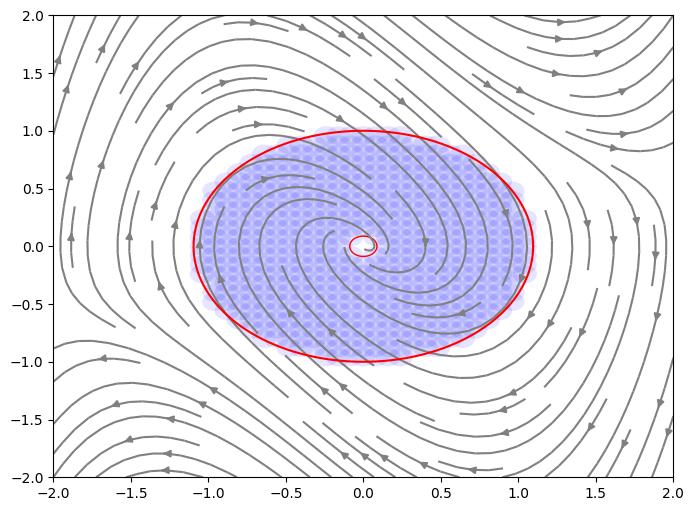

In [13]:
import matplotlib.pyplot as plt, jax

# Create grid and vectorize the flow map evaluation
x = np.linspace(-2, 2, 100)
y = np.linspace(-2, 2, 100)
X, Y = np.meshgrid(x, y)

# Stack grid points for vectorized evaluation
states = jnp.stack([X.ravel(), Y.ravel()], axis=1)
vecs = jax.vmap(sys.f)(states)
U = np.array(vecs[:, 0]).reshape(X.shape)
V = np.array(vecs[:, 1]).reshape(X.shape)

# Use streamplot to display the phase portrait
plt.figure(figsize=(8, 6))
plt.streamplot(X, Y, U, V, color="gray")

# Corrected ellipse plotting
t = np.linspace(0, 2 * np.pi, 300)
semi_major = np.sqrt(1.2 / np.abs(sys.params.rho))  # Correct semi-major axis
semi_minor = 1.  # Semi-minor axis is always 1
plt.plot(semi_major * np.cos(t), semi_minor * np.sin(t), "r-") # Corrected equation

# plt.scatter(centers[:, 0], centers[:, 1], color='b', s=1, label='Centers')
# Draw translucent circles of radius eps around each center
ax = plt.gca()
for c in centers:
    ax.add_patch(plt.Circle((c[0], c[1]), eps, color='b', alpha=0.1, fill=True, linewidth=0))

if mu is not None:
    ax = plt.gca()
    ax.add_patch(plt.Circle((0, 0), mu, color='r', fill=False, linewidth=1))